##Практика 1

**ЛР1 Курилова Е.И ПИ-3-24**

In [ ]:
import pandas as pd
import numpy as np
import IPython

**2) Контрольные вопросы**

1. Python — это высокоуровневый язык программирования общего назначения, который отличается простым и читаемым синтаксисом, динамической типизацией и интерпретируемым характером выполнения. Его ключевые особенности — кроссплатформенность, огромная стандартная библиотека и активное сообщество, благодаря чему он широко используется в веб-разработке, анализе данных, машинном обучении и автоматизации.

2. Установщик пакетов pip нужен для управления сторонними библиотеками: он позволяет скачивать, устанавливать, обновлять и удалять пакеты из репозитория PyPI, что избавляет от ручной сборки зависимостей.

3. Если говорить о специализации популярных пакетов, то Pandas предназначен для работы с табличными данными и временными рядами, NumPy — для высокопроизводительных математических вычислений и работы с многомерными массивами, а IPython представляет собой интерактивную оболочку с расширенными возможностями вроде автодополнения и встраивания графики.

4. Обычно выделяют интерактивный режим (когда команды выполняются по одной прямо в консоли или блокноте вроде Jupyter) и скриптовый режим (когда код сохраняется в файл .py и запускается целиком).

3) Google Colab — это бесплатная среда Python в браузере, которая не требует установки и даёт доступ к GPU, что сильно ускоряет обучение нейросетей. Все популярные библиотеки уже предустановлены, а файлы сохраняются на Google Диске, поэтому можно работать с любого устройства и не бояться потерять код. Удобно совместно редактировать ноутбуки в реальном времени — идеально для лабораторных и курсовых в команде. Из минусов: сеансы по времени ограничены, так что тяжёлые расчёты надолго не запустить, и для больших проектов может не хватить бесплатных ресурсов. Но в целом для учёбы и прототипирования это отличный бесплатный инструмент.

##Практика 2, 3


##Вариант 18. Анализ данных о туристических потоках
**Источник данных**: UNWTO Tourism Data

**Задание**:
1. Загрузить данные о туризме (страна, год, количество туристов, доходы).
2. Обработать пропуски, привести к единым единицам измерения.
3. Проанализировать:
* Динамику туристических потоков по регионам
* Зависимость доходов от количества туристов
* Сезонность туризма по странам
4. Построить визуализации:
* Line plot динамики туристов по годам
* Scatter plot «туристы — доходы»
* Bar chart топ-10 стран по приёму туристов
* Heatmap сезонности по месяцам и странам
* Интерактивную карту мира с показателями
5. Выявить тренды в развитии международного туризма

In [3]:
# Загрузка файла
import kagglehub
path = kagglehub.dataset_download("husnasherin/world-tourism-dataset-1999-to-2023")
print(path)
import os
print(os.listdir(path))

Using Colab cache for faster access to the 'world-tourism-dataset-1999-to-2023' dataset.
/kaggle/input/world-tourism-dataset-1999-to-2023
['world_tourism_.csv', 'eda.ipynb', '.nfs0000000063f62fd3000000d5']


In [4]:
#1 Загрузить данные о туризме (страна, год, количество туристов, доходы).
import pandas as pd
import kagglehub

file_path = "/kaggle/input/world-tourism-dataset-1999-to-2023/world_tourism_.csv"
data = pd.read_csv(file_path)

#2 Обработать пропуски, привести к единым единицам измерения.
#удаляем ненужные столбцы
data = data.drop(columns=['tourism_departures'])
data = data.drop(columns=['tourism_exports'])
data = data.drop(columns=['tourism_expenditures'])
#Заполняем пропуски медианой по стране, затем — по году
data['tourism_arrivals'] = data.groupby('country')['tourism_arrivals'].transform(
    lambda x: x.fillna(x.median())
)
data['tourism_arrivals'] = data['tourism_arrivals'].fillna(
    data.groupby('year')['tourism_arrivals'].transform('median')
)
#То же для receipts
data['tourism_receipts'] = data.groupby('country')['tourism_receipts'].transform(
    lambda x: x.fillna(x.median())
)
data['tourism_receipts'] = data['tourism_receipts'].fillna(
    data.groupby('year')['tourism_receipts'].transform('median')
)
data['arrivals_mln'] = data['tourism_arrivals'] / 1e6   # млн человек
data['receipts_bln'] = data['tourism_receipts'] / 1e9   # млрд USD
data['gdp_bln']      = data['gdp'] / 1e9                # млрд USD
# Словарь регионов по ISO-3 кодам
regions = {
    # Европа
    'ALB':'Европа','AND':'Европа','AUT':'Европа','BLR':'Европа','BEL':'Европа',
    'BIH':'Европа','BGR':'Европа','HRV':'Европа','CYP':'Европа','CZE':'Европа',
    'DNK':'Европа','EST':'Европа','FIN':'Европа','FRA':'Европа','DEU':'Европа',
    'GRC':'Европа','HUN':'Европа','ISL':'Европа','IRL':'Европа','ITA':'Европа',
    'LVA':'Европа','LTU':'Европа','LUX':'Европа','MLT':'Европа','MDA':'Европа',
    'MCO':'Европа','MNE':'Европа','NLD':'Европа','MKD':'Европа','NOR':'Европа',
    'POL':'Европа','PRT':'Европа','ROU':'Европа','RUS':'Европа','SMR':'Европа',
    'SRB':'Европа','SVK':'Европа','SVN':'Европа','ESP':'Европа','SWE':'Европа',
    'CHE':'Европа','UKR':'Европа','GBR':'Европа',
    # Азия
    'AFG':'Азия','ARM':'Азия','AZE':'Азия','BHR':'Азия','BGD':'Азия',
    'BTN':'Азия','BRN':'Азия','KHM':'Азия','CHN':'Азия','GEO':'Азия',
    'IND':'Азия','IDN':'Азия','IRN':'Азия','IRQ':'Азия','ISR':'Азия',
    'JPN':'Азия','JOR':'Азия','KAZ':'Азия','KWT':'Азия','KGZ':'Азия',
    'LAO':'Азия','LBN':'Азия','MYS':'Азия','MDV':'Азия','MNG':'Азия',
    'MMR':'Азия','NPL':'Азия','OMN':'Азия','PAK':'Азия','PHL':'Азия',
    'QAT':'Азия','SAU':'Азия','SGP':'Азия','KOR':'Азия','LKA':'Азия',
    'SYR':'Азия','TJK':'Азия','THA':'Азия','TLS':'Азия','TUR':'Азия',
    'TKM':'Азия','ARE':'Азия','UZB':'Азия','VNM':'Азия','YEM':'Азия',
    # Америка
    'ARG':'Америка','BHS':'Америка','BRB':'Америка','BLZ':'Америка','BOL':'Америка',
    'BRA':'Америка','CAN':'Америка','CHL':'Америка','COL':'Америка','CRI':'Америка',
    'CUB':'Америка','DOM':'Америка','ECU':'Америка','SLV':'Америка','GTM':'Америка',
    'GUY':'Америка','HTI':'Америка','HND':'Америка','JAM':'Америка','MEX':'Америка',
    'NIC':'Америка','PAN':'Америка','PRY':'Америка','PER':'Америка','SUR':'Америка',
    'TTO':'Америка','USA':'Америка','URY':'Америка','VEN':'Америка',
    # Африка
    'DZA':'Африка','AGO':'Африка','BEN':'Африка','BWA':'Африка','BFA':'Африка',
    'BDI':'Африка','CMR':'Африка','CPV':'Африка','CAF':'Африка','TCD':'Африка',
    'COM':'Африка','COD':'Африка','COG':'Африка','CIV':'Африка','DJI':'Африка',
    'EGY':'Африка','GNQ':'Африка','ERI':'Африка','SWZ':'Африка','ETH':'Африка',
    'GAB':'Африка','GMB':'Африка','GHA':'Африка','GIN':'Африка','GNB':'Африка',
    'KEN':'Африка','LSO':'Африка','LBR':'Африка','LBY':'Африка','MDG':'Африка',
    'MWI':'Африка','MLI':'Африка','MRT':'Африка','MUS':'Африка','MAR':'Африка',
    'MOZ':'Африка','NAM':'Африка','NER':'Африка','NGA':'Африка','RWA':'Африка',
    'STP':'Африка','SEN':'Африка','SYC':'Африка','SLE':'Африка','SOM':'Африка',
    'ZAF':'Африка','SSD':'Африка','SDN':'Африка','TZA':'Африка','TGO':'Африка',
    'TUN':'Африка','UGA':'Африка','ZMB':'Африка','ZWE':'Африка',
    # Океания
    'AUS':'Океания','FJI':'Океания','NZL':'Океания','PNG':'Океания',
    'SLB':'Океания','VUT':'Океания','WSM':'Океания',
}
data['region'] = data['country_code'].map(regions)

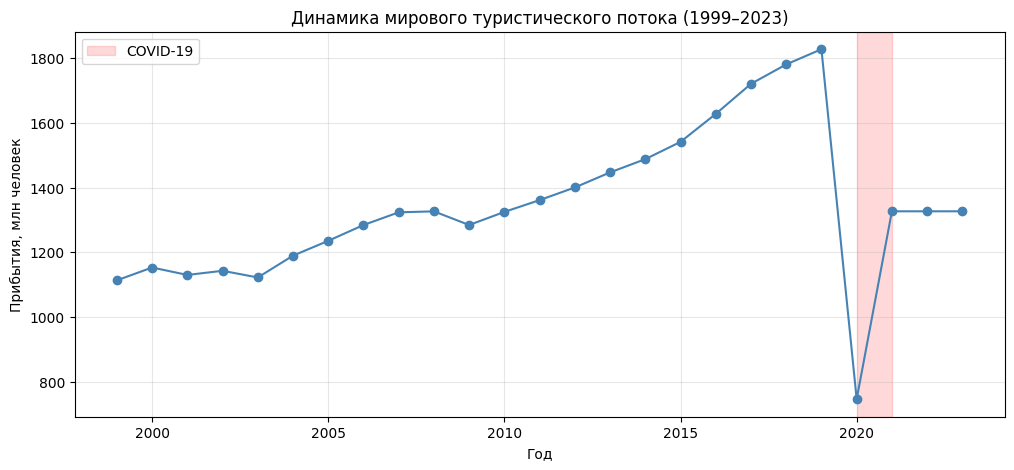

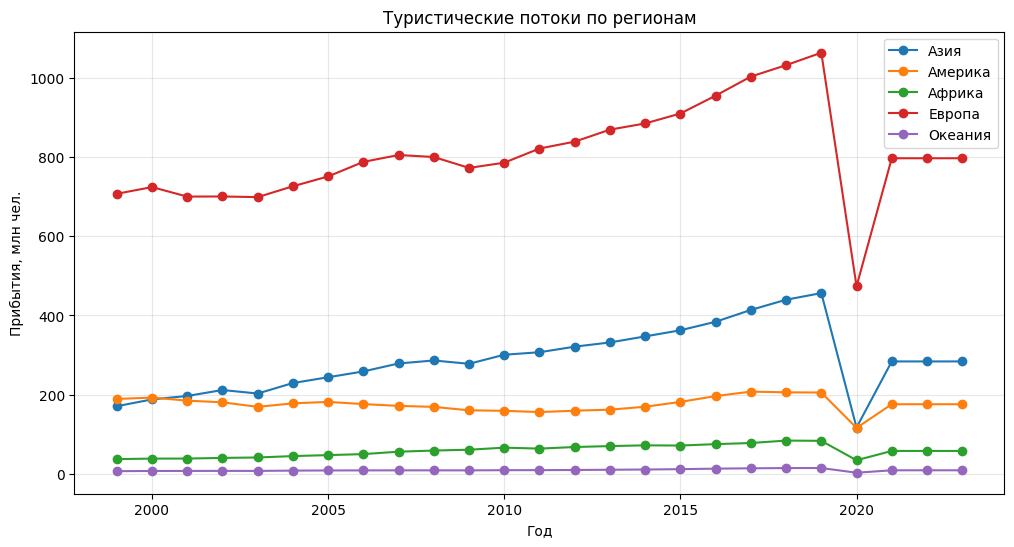

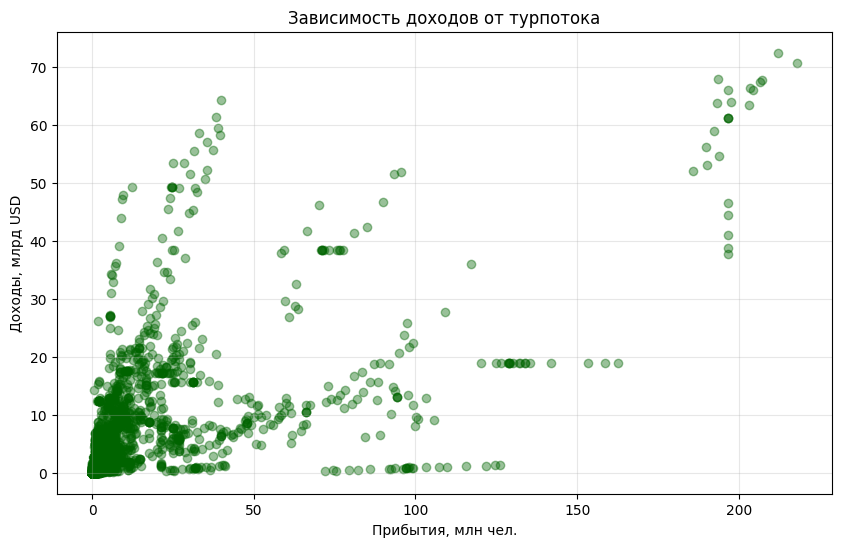

Корреляция (Пирсон): 0.654


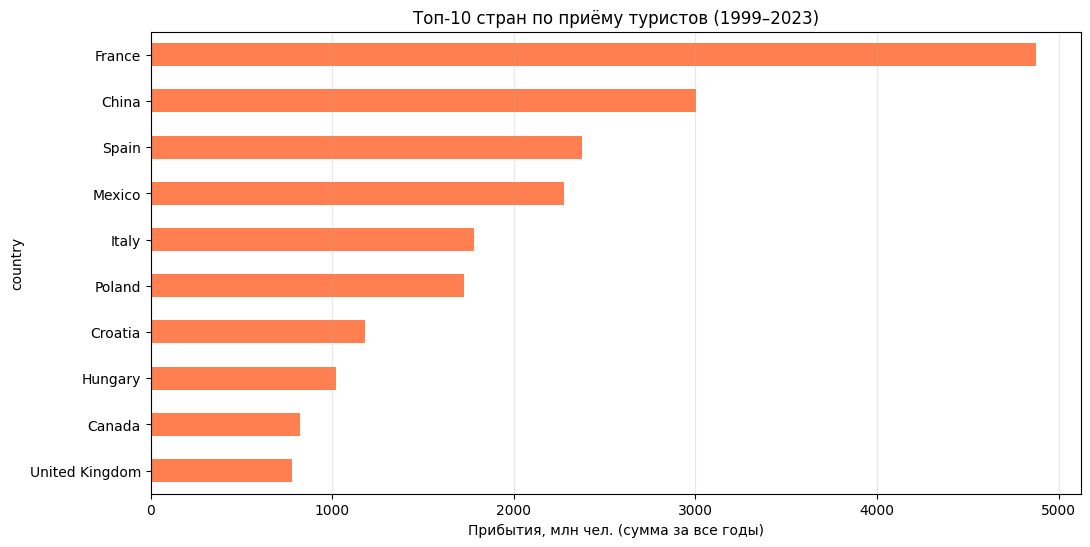

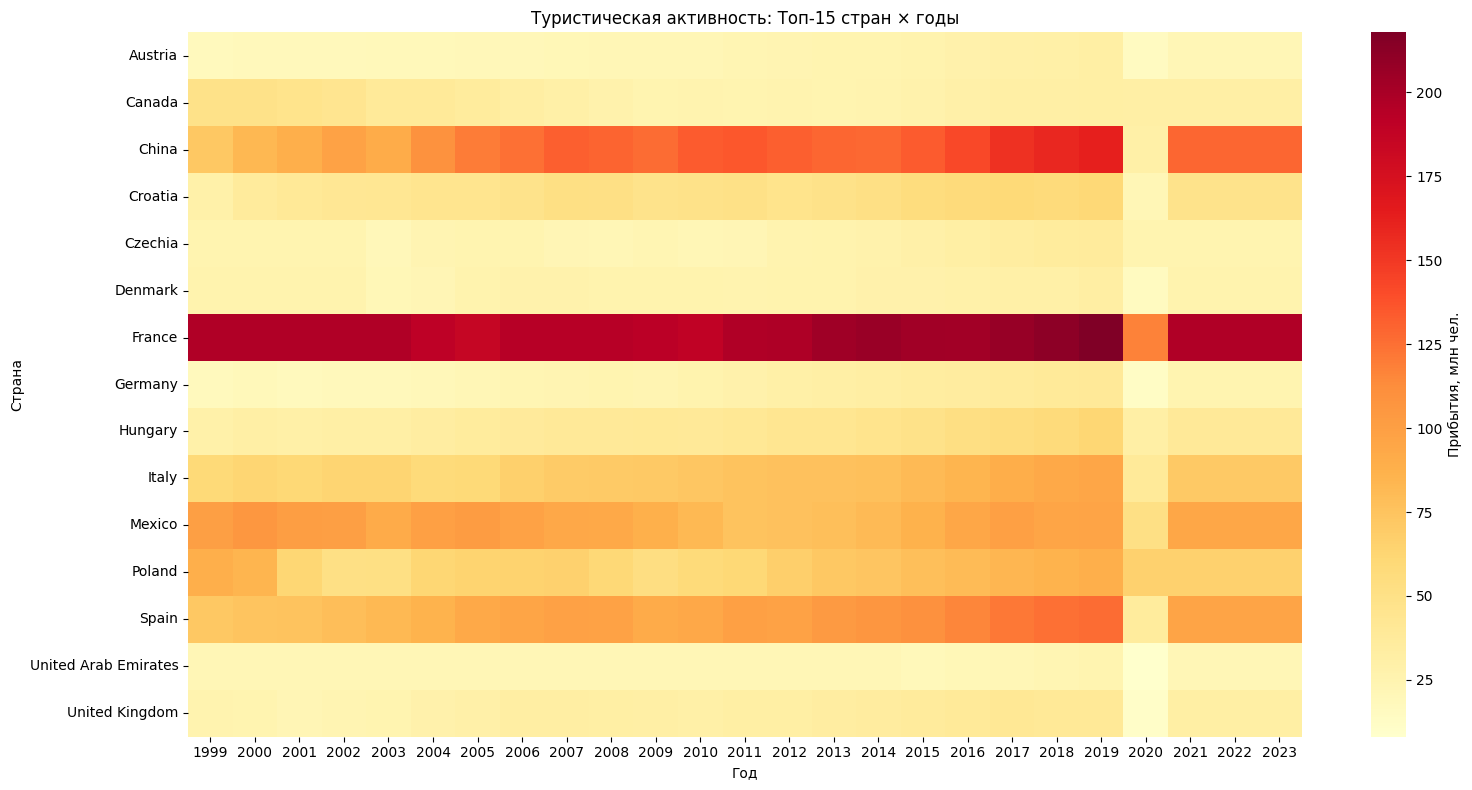

In [5]:
"""3. Проанализировать:
* Динамику туристических потоков по регионам
* Зависимость доходов от количества туристов
* Сезонность туризма по странам
4. Построить визуализации:
* Line plot динамики туристов по годам
* Scatter plot «туристы — доходы»
* Bar chart топ-10 стран по приёму туристов
* Heatmap сезонности по месяцам и странам
* Интерактивную карту мира с показателями"""

import matplotlib.pyplot as plt
# 1. LINE PLOT: мировой турпоток по годам
world = data.groupby('year')['arrivals_mln'].sum()
plt.figure(figsize=(12, 5))
plt.plot(world.index, world.values, marker='o', color='steelblue')
plt.title('Динамика мирового туристического потока (1999–2023)')
plt.xlabel('Год')
plt.ylabel('Прибытия, млн человек')
plt.grid(True, alpha=0.3)
plt.axvspan(2020, 2021, color='red', alpha=0.15, label='COVID-19')
plt.legend()
plt.show()

#  2. LINE PLOT по регионам
by_region = data.groupby(['year', 'region'])['arrivals_mln'].sum().unstack()
plt.figure(figsize=(12, 6))
for reg in by_region.columns:
    plt.plot(by_region.index, by_region[reg], marker='o', label=reg)
plt.title('Туристические потоки по регионам')
plt.xlabel('Год'); plt.ylabel('Прибытия, млн чел.')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

# 3. SCATTER: туристы vs доходы
plt.figure(figsize=(10, 6))
plt.scatter(data['arrivals_mln'], data['receipts_bln'], alpha=0.4, color='darkgreen')
plt.title('Зависимость доходов от турпотока')
plt.xlabel('Прибытия, млн чел.'); plt.ylabel('Доходы, млрд USD')
plt.grid(True, alpha=0.3)
plt.show()

# Корреляция
corr = data['arrivals_mln'].corr(data['receipts_bln'])
print(f"Корреляция (Пирсон): {corr:.3f}")

#4. BAR: Топ-10 стран
top10 = data.groupby('country')['arrivals_mln'].sum().nlargest(10)
plt.figure(figsize=(12, 6))
top10.sort_values().plot(kind='barh', color='coral')
plt.title('Топ-10 стран по приёму туристов (1999–2023)')
plt.xlabel('Прибытия, млн чел. (сумма за все годы)')
plt.grid(True, axis='x', alpha=0.3)
plt.show()

import seaborn as sns
# Heatmap: топ-15 стран × годы
top15_countries = data.groupby('country')['arrivals_mln'].sum().nlargest(15).index
heat = data[data['country'].isin(top15_countries)] \
    .pivot_table(index='country', columns='year', values='arrivals_mln')
plt.figure(figsize=(16, 8))
sns.heatmap(heat, cmap='YlOrRd', cbar_kws={'label': 'Прибытия, млн чел.'})
plt.title('Туристическая активность: Топ-15 стран × годы')
plt.xlabel('Год'); plt.ylabel('Страна')
plt.tight_layout()
plt.show()

import plotly.express as px
# Суммарные прибытия по странам
map_data = data.groupby(['country', 'country_code'], as_index=False)['arrivals_mln'].sum()

fig = px.choropleth(
    map_data,
    locations='country_code',
    color='arrivals_mln',
    hover_name='country',
    color_continuous_scale='Viridis',
    title='Мировой туристический поток, 1999–2023 (сумма)',
    labels={'arrivals_mln': 'Прибытия, млн чел.'}
)
fig.show()

In [6]:
#5. Тренды в развитии международного туризма
import matplotlib.pyplot as plt

world = data.groupby('year')['arrivals_mln'].sum()
receipts = data.groupby('year')['receipts_bln'].sum()

y99, y19, y20, y23 = world[1999], world[2019], world[2020], world[2023]

print('Количество туристов по годам')
print("1999:", round(world[1999]), "млн")
print("2019:", round(world[2019]), "млн")
print("2020:", round(world[2020]), "млн")
print("2023:", round(world[2023]), "млн")
print()
print(f"Рост 1999 -> 2019:     +{(y19/y99-1)*100:.0f}%  (CAGR +{((y19/y99)**(1/20)-1)*100:.1f}%/год)")
print(f"Падение 2019 -> 2020:  {(y20/y19-1)*100:.0f}%")
print(f"Восстановл. 2023:   {y23/y19*100:.0f}% от уровня 2019")
print(f"Корреляция туристы <-> доходы: {data['arrivals_mln'].corr(data['receipts_bln']):.3f}")

# Доходы
r99, r19, r23 = receipts[1999], receipts[2019], receipts[2023]
print(f"\nДоходы: \n1999 — ${r99:.0f} млрд \n2019 — ${r19:.0f} млрд \n2023 — ${r23:.0f} млрд")
print(f"\nСредний чек: \n1999 — ${r99*1e9/(y99*1e6):.0f} \n2019 — ${r19*1e9/(y19*1e6):.0f} \n2023 — ${r23*1e9/(y23*1e6):.0f}")

Количество туристов по годам
1999: 1114 млн
2019: 1827 млн
2020: 746 млн
2023: 1327 млн

Рост 1999 -> 2019:     +64%  (CAGR +2.5%/год)
Падение 2019 -> 2020:  -59%
Восстановл. 2023:   73% от уровня 2019
Корреляция туристы <-> доходы: 0.654

Доходы: 
1999 — $388 млрд 
2019 — $1018 млрд 
2023 — $645 млрд

Средний чек: 
1999 — $348 
2019 — $557 
2023 — $486


**1. Какие инструментальные средства используются для организации рабочего места специалиста Data Science?**

Для организации рабочего места специалиста по анализу данных и машинному обучению используется несколько категорий инструментов. Во-первых, это среда разработки — чаще всего Jupyter Notebook или JupyterLab, которые позволяют выполнять код по ячейкам, сразу видеть результат и оформлять отчёт с графиками и текстом. В ходе практических работ я использовал именно Jupyter в Google Colab, что удобно, так как не требует установки Python на компьютер и даёт бесплатный доступ к вычислительным ресурсам. Во-вторых, это сам язык программирования Python с набором библиотек. В-третьих, системы контроля версий (Git, GitHub) для хранения кода и совместной работы. В-четвёртых, источники данных — репозитории UCI, Kaggle, UNWTO, откуда загружаются наборы данных. Также используются библиотеки для загрузки данных (kagglehub, scipy), обработки (pandas, numpy), визуализации (matplotlib, seaborn, plotly) и машинного обучения (scikit-learn). В совокупности это и составляет рабочее место Data Science-специалиста.

**2. Какие библиотеки Python используются в области машинного обучения? Дайте краткую характеристику каждой.**

Основных библиотек несколько. **NumPy** — базовая библиотека для работы с многомерными массивами и математическими операциями; на ней построены почти все остальные. **pandas** — для работы с табличными данными: загрузка CSV, обработка пропусков, группировки, сводные таблицы; именно её я использовал в практических работах для анализа данных о кредитах и туризме. **Matplotlib** — базовая библиотека визуализации: линейные графики, scatter plot, столбчатые диаграммы. **Seaborn** — надстройка над Matplotlib для статистической визуализации: heatmap, boxplot, распределения. **Plotly** — интерактивная визуализация, в том числе карты мира (choropleth). **Scikit-learn** — основная библиотека классического машинного обучения: классификация, регрессия, кластеризация, метрики, разбиение на train/test. **SciPy** — научные вычисления, методы оптимизации, статистика; из неё я использовал genfromtxt для загрузки данных об ирисах. **TensorFlow** и **PyTorch** — библиотеки для глубокого обучения и нейросетей. **Statsmodels** — статистическое моделирование и проверка гипотез.

**3. Почему при реализации систем машинного обучения широкое распространение получили библиотеки Python?**

Причин несколько. Во-первых, Python — простой и читаемый язык с низким порогом входа, что позволяет быстро писать и отлаживать код. Во-вторых, у Python огромная экосистема готовых библиотек: pandas, NumPy, scikit-learn, TensorFlow — всё это позволяет решать задачи анализа данных и ML без написания алгоритмов с нуля. В-третьих, активное сообщество: множество примеров, документации, ответов на Stack Overflow, что ускоряет обучение и разработку. В-четвёртых, интеграция с другими инструментами: Jupyter Notebook, Git, облачные платформы (Colab, Kaggle), базы данных. В-пятых, библиотеки Python написаны на C/C++ под капотом (NumPy, TensorFlow), поэтому работают быстро, несмотря на то что сам Python — интерпретируемый язык. Наконец, Python одинаково хорошо подходит и для исследования данных, и для продакшена, что делает его универсальным инструментом для всего цикла ML-проекта — от загрузки данных до внедрения модели.

**Вывод:**
Таким образом, обе работы дали мне полное представление о цикле работы с данными: загрузка → предобработка → разведочный анализ → визуализация → выводы. Я освоил библиотеки pandas, numpy, matplotlib, seaborn и plotly, научился работать с реальными «грязными» данными и формулировать содержательные выводы на основе графиков и сводных таблиц. Эти навыки — база для построения моделей машинного обучения и решения прикладных задач анализа данных.